# Predicción de Churn con Regresión Logística

**Problema:** una empresa de telecomunicaciones quiere anticiparse a los clientes que van a dar de baja el servicio (*churn*). Si el modelo detecta a tiempo a quienes están por irse, el equipo comercial puede contactarlos con una oferta de retención.

**Dataset:** *Telco Customer Churn* (IBM), con 7.043 clientes y 21 columnas: datos del contrato, servicios contratados, cargos mensuales y la columna `Churn` (`Yes` si el cliente se fue, `No` si se quedó).

**Objetivo:** entrenar un modelo de clasificación binaria, evaluarlo en un conjunto de prueba con Accuracy, Precision, Recall, F1-Score y matriz de confusión, e interpretar los resultados en términos de negocio.

## 1. Carga de datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = pd.read_csv("data/telco_churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


Solo el 26,5% de los clientes abandona: las clases están **desbalanceadas**. Esto es importante para interpretar las métricas más adelante.

## 2. Limpieza y preparación

- `TotalCharges` viene como texto porque tiene 11 celdas vacías. Son clientes nuevos (`tenure = 0`) que todavía no tienen cargos acumulados. Se convierte a número y esos 11 nulos se completarán dentro del pipeline, **después** de dividir los datos.
- `customerID` es solo un identificador, no aporta información para predecir, así que se elimina.
- El objetivo `Churn` se convierte a 1 (abandona) y 0 (se queda).

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Nulos en TotalCharges:", df["TotalCharges"].isna().sum())
print("Tenure de esos clientes:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())

df = df.drop(columns="customerID")

y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns="Churn")

columnas_numericas = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
columnas_categoricas = [c for c in X.columns if c not in columnas_numericas]
print(len(columnas_numericas), "variables numéricas y", len(columnas_categoricas), "categóricas")

Nulos en TotalCharges: 11
Tenure de esos clientes: [0]
4 variables numéricas y 15 categóricas


## 3. División en Train y Test (80/20)

La división se hace **antes de ajustar cualquier transformación o modelo**, para que ningún dato de prueba influya en el entrenamiento. Se usa `stratify=y` para que ambos conjuntos mantengan la misma proporción de clientes que abandonan.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} clientes | Test: {len(X_test)} clientes")
print(f"% de churn en train: {y_train.mean():.1%} | en test: {y_test.mean():.1%}")

Train: 5634 clientes | Test: 1409 clientes
% de churn en train: 26.5% | en test: 26.5%


## 4. Modelo base: Regresión Logística

El preprocesamiento y el modelo se encadenan en un único `Pipeline`:
- **Numéricas:** imputación de nulos con la mediana y escalado con `StandardScaler`.
- **Categóricas:** imputación con el valor más frecuente y `OneHotEncoder` (con `handle_unknown="ignore"` para tolerar categorías nuevas).

El pipeline se ajusta (`fit`) solo con los datos de entrenamiento.

In [5]:
def construir_modelo(class_weight=None):
    numericas = Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
    ])
    categoricas = Pipeline([
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("codificador", OneHotEncoder(handle_unknown="ignore")),
    ])
    preprocesador = ColumnTransformer([
        ("num", numericas, columnas_numericas),
        ("cat", categoricas, columnas_categoricas),
    ])
    return Pipeline([
        ("preprocesamiento", preprocesador),
        ("modelo", LogisticRegression(max_iter=1000, class_weight=class_weight)),
    ])


modelo_base = construir_modelo()
modelo_base.fit(X_train, y_train)
pred_base = modelo_base.predict(X_test)

## 5. Métricas del modelo base (sobre el conjunto de prueba)

In [6]:
def calcular_metricas(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred),
        "Recall": recall_score(y_real, y_pred),
        "F1-Score": f1_score(y_real, y_pred),
    }


metricas_base = calcular_metricas(y_test, pred_base)
for nombre, valor in metricas_base.items():
    print(f"{nombre:10s}: {valor:.3f}")

print()
print(classification_report(y_test, pred_base, target_names=["Se queda", "Abandona"]))

Accuracy  : 0.806
Precision : 0.657
Recall    : 0.559
F1-Score  : 0.604

              precision    recall  f1-score   support

    Se queda       0.85      0.89      0.87      1035
    Abandona       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Matriz de confusión del modelo base

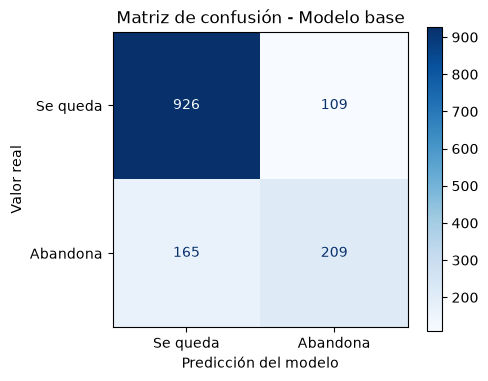

In [7]:
def graficar_matriz(y_real, y_pred, titulo):
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_real,
        y_pred,
        display_labels=["Se queda", "Abandona"],
        cmap="Blues",
        ax=ax,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Valor real")
    plt.tight_layout()
    plt.show()


graficar_matriz(y_test, pred_base, "Matriz de confusión - Modelo base")

## 6. Segundo modelo: priorizando detectar a quienes se van

Como solo el 26,5% de los clientes abandona, el modelo base tiende a favorecer a la clase mayoritaria (los que se quedan). Con `class_weight="balanced"` se le da más peso a los errores sobre los clientes que abandonan, para que aprenda a detectarlos mejor.

Accuracy  : 0.738
Precision : 0.504
Recall    : 0.783
F1-Score  : 0.614


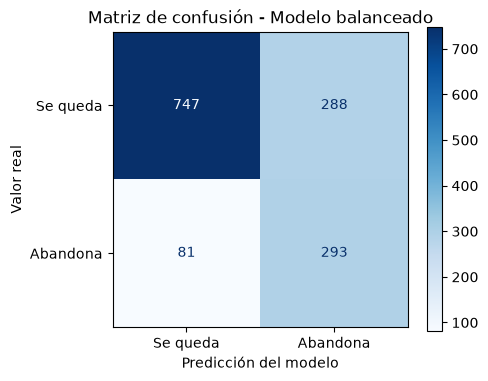

In [8]:
modelo_balanceado = construir_modelo(class_weight="balanced")
modelo_balanceado.fit(X_train, y_train)
pred_balanceado = modelo_balanceado.predict(X_test)

metricas_balanceado = calcular_metricas(y_test, pred_balanceado)
for nombre, valor in metricas_balanceado.items():
    print(f"{nombre:10s}: {valor:.3f}")

graficar_matriz(y_test, pred_balanceado, "Matriz de confusión - Modelo balanceado")

### Comparación de ambos modelos

In [9]:
comparacion = pd.DataFrame({
    "Modelo base": metricas_base,
    "Modelo balanceado": metricas_balanceado,
}).round(3)
comparacion

,Modelo base,Modelo balanceado
Accuracy,0.806,0.738
Precision,0.657,0.504
Recall,0.559,0.783
F1-Score,0.604,0.614


## 7. Impacto en el negocio

Para medir el costo de los errores se calcula, sobre el conjunto de prueba, cuántos clientes que se van **no** fueron detectados (falsos negativos) y cuánta facturación mensual representan (`MonthlyCharges`).

In [10]:
def impacto(y_real, y_pred, X_eval):
    se_van = y_real.values == 1
    detectado = y_pred == 1
    falso_negativo = se_van & ~detectado
    falso_positivo = ~se_van & detectado
    return {
        "Clientes que se van": int(se_van.sum()),
        "Detectados (verdaderos positivos)": int((se_van & detectado).sum()),
        "No detectados (falsos negativos)": int(falso_negativo.sum()),
        "Falsas alarmas (falsos positivos)": int(falso_positivo.sum()),
        "Facturación mensual no detectada (USD)": round(
            float(X_eval.loc[falso_negativo, "MonthlyCharges"].sum())
        ),
    }


tabla_impacto = pd.DataFrame({
    "Modelo base": impacto(y_test, pred_base, X_test),
    "Modelo balanceado": impacto(y_test, pred_balanceado, X_test),
})
tabla_impacto

,Modelo base,Modelo balanceado
Clientes que se van,374,374
Detectados (verdaderos positivos),209,293
No detectados (falsos negativos),165,81
Falsas alarmas (falsos positivos),109,288
Facturación mensual no detectada (USD),10779,4800


## 8. Conclusión

**La métrica más importante para el problema de churn es el Recall** (acompañado del F1-Score para controlar que no se descuide la Precision).

**Por qué no alcanza con la Accuracy.** El modelo base tiene una Accuracy de 80,6%, que parece muy buena. Pero como el 73,5% de los clientes se queda, un modelo que dijera "nadie se va" ya acertaría el 73,5% de las veces sin detectar a nadie. La Accuracy esconde el problema real.

**Por qué el Recall.** Un falso negativo es un cliente que se va y que el modelo no detectó: no recibe ninguna acción de retención y la empresa pierde toda su facturación futura. En el conjunto de prueba, cada cliente que el modelo base no detectó representa en promedio unos USD 65 de facturación al mes. Un falso positivo, en cambio, es un cliente que se iba a quedar y recibe una oferta o un llamado de más: un costo acotado y conocido (un descuento o una llamada). Mientras ese costo sea menor que lo que se pierde cuando un cliente se va, conviene aceptar más falsas alarmas a cambio de detectar a más clientes en riesgo.

**Qué muestran los resultados:**

| | Modelo base | Modelo balanceado |
|---|---|---|
| Recall | 0,559 | 0,783 |
| Precision | 0,657 | 0,504 |
| F1-Score | 0,604 | 0,614 |
| Accuracy | 0,806 | 0,738 |
| Clientes que se van y no se detectan | 165 de 374 | 81 de 374 |
| Falsas alarmas | 109 | 288 |
| Facturación mensual no detectada | USD 10.779 | USD 4.800 |

El modelo balanceado cede Accuracy (de 80,6% a 73,8%) y Precision (hay 179 falsas alarmas más), pero detecta a 84 clientes en riesgo adicionales y reduce a menos de la mitad la facturación mensual que se escapa sin ser detectada (unos USD 6.000 al mes en este conjunto de prueba). El F1-Score además mejora levemente.

**Recomendación:** para una campaña de retención conviene el **modelo balanceado**, porque el costo de dejar ir a un cliente es mayor que el de contactar a uno de más.

**Limitaciones:** el cálculo supone que todo cliente contactado a tiempo se retiene, y en la práctica no es así. Además, se usó el umbral de decisión por defecto (0,5); ajustarlo permitiría elegir con más precisión el balance entre detectar más clientes y limitar las falsas alarmas, según el costo real de la campaña de retención.